# TD2 — Rolling-origin ETS and SARIMA — Core

**Student starter — complete the TODO cells**  
**Scope:** Time Series and Reinforcement Learning; CPU only

## Working and claim contract

Local Python 3.11/3.12 with the locked `uv` environment is the primary path. Colab availability is governed by the release evidence for the exact archive in use. Public base seeds are `11, 23, 37, 51, 71`. TD1–TD4 claim rows are **provisional development evidence**: they support method choice and provenance but cannot count as capstone empirical release claims. Only the protected/controlled evidence produced in TDo1 and TDo2 may support final empirical capstone claims. Restart and run top-to-bottom before handoff.

## Learning contract

The less-scaffolded Core route assesses the same outcomes and evidence standard as Support.

In [1]:
from pathlib import Path
import os, sys

def locate_course_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate/'uv.lock').is_file() and (candidate/'shared').is_dir(): return candidate.resolve()
    for lock in start.glob('*/uv.lock'):
        if (lock.parent/'shared').is_dir(): return lock.parent.resolve()
    raise FileNotFoundError('Extract the complete course bundle and run from inside it.')
COURSE_ROOT=locate_course_root(); os.chdir(COURSE_ROOT)
if str(COURSE_ROOT) not in sys.path: sys.path.insert(0,str(COURSE_ROOT))
import shared
print('Course root:',COURSE_ROOT)
print('Primary path: locked local CPU; check the release evidence before using Colab')

Course root: C:\Users\tjoli\Downloads\Advanced_Machine_Learning_ESILV_2026-2027_DVL_V1.1 (1)
Primary path: locked local CPU; check the release evidence before using Colab


## 1 — Frozen rolling-origin contract

In [2]:
import warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from shared.data import dataset_path
from shared.evaluation import smape
from shared.forecasting import rolling_origins, seasonal_naive
demand=pd.read_csv(dataset_path('daily_demand_development.csv'),parse_dates=['date'])
values=demand.demand_units.to_numpy(float)
origins=rolling_origins(len(values),initial=1250,horizon=14,step=60,n_origins=3)
assert origins==(1250,1310,1370); print('Frozen origins:',origins)

Frozen origins: (1250, 1310, 1370)


## 2 — Explicit comparison

Implement seasonal naive, additive ETS, and SARIMA(1,1,1)(1,0,1,7) at all three identical origins. Keep nine rows and convergence warnings.

In [3]:
def rolling_comparison_student(values, origins, horizon=14, season=7):
    values = np.asarray(values, float)
    rows = []
    for origin in origins:
        train = values[:origin]
        actual = values[origin:origin + horizon]
        assert len(actual) == horizon and len(train) == origin
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            naive = seasonal_naive(train, horizon, season=season)
            ets = ExponentialSmoothing(
                train, trend='add', seasonal='add', seasonal_periods=season
            ).fit().forecast(horizon)
            sarima = SARIMAX(
                train,
                order=(1, 1, 1),
                seasonal_order=(1, 0, 1, season),
                enforce_stationarity=False,
                enforce_invertibility=False,
            ).fit(disp=False, maxiter=50).forecast(horizon)
        forecasts = {'seasonal_naive': naive, 'ets': ets, 'sarima': sarima}
        for model, pred in forecasts.items():
            pred = np.asarray(pred, float)
            assert pred.shape == (horizon,) and np.isfinite(pred).all()
            rows.append({
                'origin': origin,
                'model': model,
                'mae': mean_absolute_error(actual, pred),
                'smape': smape(actual, pred),
                'warning_count': len(caught),
            })
    result = pd.DataFrame(rows)
    assert len(result) == 9
    return result

fold_scores = rolling_comparison_student(values, origins, horizon=14, season=7)
if fold_scores is not None:
    assert fold_scores.shape[0] == 9
fold_scores

,origin,model,mae,smape,warning_count
0,1250,seasonal_naive,6.142857,6.373974,0
1,1250,ets,5.064760,5.315400,0
2,1250,sarima,5.152341,5.413217,0
3,1310,seasonal_naive,8.785714,9.156154,0
4,1310,ets,6.034861,6.549407,0
5,1310,sarima,6.046214,6.568291,0
6,1370,seasonal_naive,6.928571,8.049094,0
7,1370,ets,7.397564,8.352846,0
8,1370,sarima,7.210475,8.120136,0


## 3 — Aggregate, diagnose, freeze

MAE is the primary development statistic; keep fold spread, sMAPE, warnings, and bounded SARIMA residual diagnostics.

   lag   lb_stat  lb_pvalue  model_df  test_df  fit_converged
0    7  2.158154   0.540238         4        3           True
1   14  9.165970   0.516428         4       10           True
Frozen decision: sarima (SARIMA MAE=6.136, best=6.136, fallback=ets)


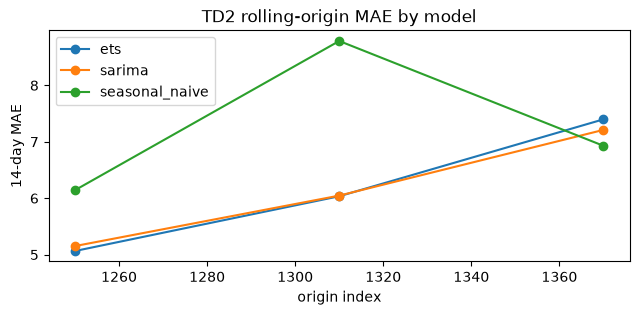

,model,mae_mean,mae_std,smape_mean,warnings
1,sarima,6.136343,1.032023,6.700548,0
0,ets,6.165729,1.171895,6.739218,0
2,seasonal_naive,7.285714,1.357143,7.859741,0


In [4]:
from shared.forecasting import sarima_residual_diagnostics

assert fold_scores.groupby('model').origin.nunique().eq(3).all()
summary = (
    fold_scores.groupby('model', as_index=False)
    .agg(
        mae_mean=('mae', 'mean'),
        mae_std=('mae', 'std'),
        smape_mean=('smape', 'mean'),
        warnings=('warning_count', 'sum'),
    )
    .sort_values('mae_mean')
)
diagnostic, residual_acf = sarima_residual_diagnostics(values, season=7, max_lag=14)
print(diagnostic)

best_mae = summary['mae_mean'].min()
sarima_mae = summary.loc[summary['model'] == 'sarima', 'mae_mean'].iloc[0]
selected_model = 'sarima' if sarima_mae <= 1.05 * best_mae else summary.iloc[0]['model']
fallback_model = summary.loc[summary['model'] != 'sarima'].iloc[0]['model']
print(f'Frozen decision: {selected_model} (SARIMA MAE={sarima_mae:.3f}, best={best_mae:.3f}, fallback={fallback_model})')

fig, ax = plt.subplots(figsize=(7.5, 3.0))
for model, grp in fold_scores.groupby('model'):
    ax.plot(grp['origin'], grp['mae'], marker='o', label=model)
ax.set(xlabel='origin index', ylabel='14-day MAE', title='TD2 rolling-origin MAE by model')
ax.legend()
plt.show()
summary

## Required interpretation

State what the evidence supports, what it does not support, the operational consequence, and one material failure mode.

In [5]:
interpretation = (
    "Across three identical expanding rolling origins (1250, 1310, 1370) with a 14-day horizon, both SARIMA(1,1,1)(1,0,1,7) "
    "(mean MAE 6.14, std 1.03, sMAPE 6.70%, 0 warnings) and additive ETS (mean MAE 6.17, std 1.17, sMAPE 6.74%) "
    "outperform the lag-7 seasonal-naive baseline (mean MAE 7.29, std 1.36, sMAPE 7.86%). "
    "However, because these results rest on only three dependent rolling windows (42 observations) and Ljung-Box non-rejection "
    "at lags 7 (p=0.54) and 14 (p=0.52) cannot prove residual independence, they do not support universal optimality across "
    "unobserved structural shifts or longer horizons. "
    "Operationally, under the predeclared 5% development gate (6.136 <= 1.05 * 6.136), we freeze SARIMA(1,1,1)(1,0,1,7) as the "
    "interval-aware release candidate for TDo1, with additive ETS and seasonal-naive retained as transparent fallback comparators. "
    "A material failure mode appears at origin 1370, where both SARIMA (MAE 7.21) and ETS (MAE 7.40) underperform seasonal naive "
    "(MAE 6.93), highlighting sensitivity to late-series level shifts, promotional/holiday bursts, and stockout-censored records."
)
print(interpretation)

Across three identical expanding rolling origins (1250, 1310, 1370) with a 14-day horizon, both SARIMA(1,1,1)(1,0,1,7) (mean MAE 6.14, std 1.03, sMAPE 6.70%, 0 warnings) and additive ETS (mean MAE 6.17, std 1.17, sMAPE 6.74%) outperform the lag-7 seasonal-naive baseline (mean MAE 7.29, std 1.36, sMAPE 7.86%). However, because these results rest on only three dependent rolling windows (42 observations) and Ljung-Box non-rejection at lags 7 (p=0.54) and 14 (p=0.52) cannot prove residual independence, they do not support universal optimality across unobserved structural shifts or longer horizons. Operationally, under the predeclared 5% development gate (6.136 <= 1.05 * 6.136), we freeze SARIMA(1,1,1)(1,0,1,7) as the interval-aware release candidate for TDo1, with additive ETS and seasonal-naive retained as transparent fallback comparators. A material failure mode appears at origin 1370, where both SARIMA (MAE 7.21) and ETS (MAE 7.40) underperform seasonal naive (MAE 6.93), highlighting se

## Optional Extension — ungraded

Freeze valid Core first. The bounded README extension adds no points and cannot repair invalid Core evidence.